In [ ]:
# CELL 1: Download & Persiapan Semua Dataset (Kaggle, TrashNet, MJU-Waste)
import os
import zipfile
import subprocess

# 1. Download Waste Classification Data (Kaggle) via kagglehub
print("1. Mengunduh Waste Classification Data dari Kaggle...")
import kagglehub
kaggle_path = kagglehub.dataset_download("techsash/waste-classification-data")
print("   Lokasi dataset Kaggle:", kaggle_path)

# 2. Clone repo GitHub TrashNet & ekstrak dataset-resized.zip
print("\n2. Mengunduh dataset TrashNet dari GitHub...")
if not os.path.exists("trashnet"):
    !git clone https://github.com/garythung/trashnet.git
trashnet_zip = "trashnet/data/dataset-resized.zip"
if os.path.exists(trashnet_zip) and not os.path.exists("trashnet_extracted"):
    with zipfile.ZipFile(trashnet_zip, 'r') as z:
        z.extractall("trashnet_extracted")
    print("   TrashNet berhasil diekstrak!")

# 3. Download MJU-Waste dari Google Drive menggunakan gdown
print("\n3. Mengunduh dataset MJU-Waste dari Google Drive...")
try:
    import gdown
except ImportError:
    !pip install gdown -q
    import gdown

# Buat folder tujuan ekstraksi jika belum ada
os.makedirs("/content/gdrive_dataset", exist_ok=True)
zip_target = "/content/dataset_gdrive.zip"

# Download otomatis menggunakan --fuzzy agar aman dari error permission/format link GDrive
if not os.path.exists(zip_target) or os.path.getsize(zip_target) == 0:
    !gdown --fuzzy "https://drive.google.com/file/d/1o101UBJGeeMPpI-DSY6oh-tLk9AHXMny/view?usp=sharing" -O {zip_target}

# Ekstrak file zip Google Drive secara otomatis
if os.path.exists(zip_target):
    with zipfile.ZipFile(zip_target, 'r') as z:
        z.extractall("/content/gdrive_dataset")
    print("   MJU-Waste berhasil diekstrak ke /content/gdrive_dataset!")

print("3. Isi folder dataset Google Drive:", os.listdir("/content/gdrive_dataset"))

1. Mengunduh Waste Classification Data dari Kaggle...
Using Colab cache for faster access to the 'waste-classification-data' dataset.
   Lokasi dataset Kaggle: /kaggle/input/waste-classification-data

2. Mengunduh dataset TrashNet dari GitHub...
Cloning into 'trashnet'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 45 (delta 14), reused 8 (delta 8), pack-reused 24 (from 1)
Receiving objects: 100% (45/45), 40.64 MiB | 7.27 MiB/s, done.
Resolving deltas: 100% (14/14), done.
   TrashNet berhasil diekstrak!

3. Mengunduh dataset MJU-Waste dari Google Drive...
Downloading...
From (original): https://drive.google.com/uc?id=1o101UBJGeeMPpI-DSY6oh-tLk9AHXMny
From (redirected): https://drive.google.com/uc?id=1o101UBJGeeMPpI-DSY6oh-tLk9AHXMny&confirm=t&uuid=76989d50-7300-4a3c-a4d3-baf0ef70ef8c
To: /content/dataset_gdrive.zip
100% 1.45G/1.45G [00:14<00:00, 101MB/s] 
   MJU-Waste berhasil diekst

In [ ]:
# CELL 2 (FINAL & LENGKAP - KAGGLE, TRASHNET, MJU-WASTE):
import os
import hashlib
import pandas as pd
import numpy as np
from PIL import Image

records = []
corrupted_files = 0
hashes = set()
duplicate_count = 0
total_size_bytes = 0

# --- 1. SCANNING DATASET KAGGLE ---
base_dir_kaggle = os.path.join(kaggle_path, "DATASET")
if not os.path.exists(base_dir_kaggle):
    for root, dirs, files in os.walk(kaggle_path):
        if "TRAIN" in dirs and "TEST" in dirs:
            base_dir_kaggle = root
            break

label_map_kaggle = {"O": "Non-Recyclable (0)", "R": "Recyclable (1)"}

if os.path.exists(base_dir_kaggle):
    for split in ["TRAIN", "TEST"]:
        split_dir = os.path.join(base_dir_kaggle, split)
        if not os.path.exists(split_dir): continue
        for cls in ["O", "R"]:
            cls_dir = os.path.join(split_dir, cls)
            if not os.path.exists(cls_dir): continue
            for fname in os.listdir(cls_dir):
                fpath = os.path.join(cls_dir, fname)
                if not os.path.isfile(fpath): continue

                fsize = os.path.getsize(fpath)
                total_size_bytes += fsize

                with open(fpath, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()
                is_dup = file_hash in hashes
                if is_dup: duplicate_count += 1
                else: hashes.add(file_hash)

                try:
                    with Image.open(fpath) as img:
                        w, h = img.size
                        mode = img.mode
                    records.append({
                        "image_path": fpath, "sumber_dataset": "Kaggle", "split_asal": split,
                        "label_raw": cls, "label_biner": 1 if cls == "R" else 0, "kategori": label_map_kaggle[cls],
                        "width": w, "height": h, "aspect_ratio": round(w / h, 2),
                        "color_mode": mode, "file_size_kb": round(fsize / 1024, 2), "is_duplicate": is_dup
                    })
                except: corrupted_files += 1

# --- 2. SCANNING DATASET TRASHNET (Fleksibel ke dalam subfolder kelas) ---
trashnet_classes = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
for root, dirs, files in os.walk("."):
    if "trashnet" in root.lower() or "dataset-resized" in root.lower():
        base_name = os.path.basename(root).lower()
        if base_name in trashnet_classes:
            is_rec = 0 if base_name == "trash" else 1
            kat_teks = "Non-Recyclable (0)" if is_rec == 0 else "Recyclable (1)"
            for fname in files:
                if not fname.lower().endswith(('.png', '.jpg', '.jpeg')): continue
                fpath = os.path.join(root, fname)
                if not os.path.isfile(fpath): continue

                fsize = os.path.getsize(fpath)
                total_size_bytes += fsize
                with open(fpath, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()
                is_dup = file_hash in hashes
                if is_dup: duplicate_count += 1
                else: hashes.add(file_hash)

                try:
                    with Image.open(fpath) as img:
                        w, h = img.size
                        mode = img.mode
                    records.append({
                        "image_path": fpath, "sumber_dataset": "TrashNet", "split_asal": "Combined",
                        "label_raw": base_name, "label_biner": is_rec, "kategori": kat_teks,
                        "width": w, "height": h, "aspect_ratio": round(w / h, 2),
                        "color_mode": mode, "file_size_kb": round(fsize / 1024, 2), "is_duplicate": is_dup
                    })
                except: corrupted_files += 1

# --- 3. SCANNING DATASET MJU-WASTE (Dari /content/gdrive_dataset) ---
mju_img_dir = "/content/gdrive_dataset"
if not os.path.exists(mju_img_dir):
    mju_img_dir = "gdrive_dataset"

if os.path.exists(mju_img_dir):
    for root, dirs, files in os.walk(mju_img_dir):
        for fname in files:
            if not fname.lower().endswith(('.png', '.jpg', '.jpeg')): continue
            fpath = os.path.join(root, fname)
            fsize = os.path.getsize(fpath)
            total_size_bytes += fsize

            with open(fpath, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()
            is_dup = file_hash in hashes
            if is_dup: duplicate_count += 1
            else: hashes.add(file_hash)

            try:
                with Image.open(fpath) as img:
                    w, h = img.size
                    mode = img.mode
                records.append({
                    "image_path": fpath, "sumber_dataset": "MJU-Waste", "split_asal": "Google Drive",
                    "label_raw": "MJU_Dataset", "label_biner": 1, "kategori": "Recyclable (1)",
                    "width": w, "height": h, "aspect_ratio": round(w / h, 2),
                    "color_mode": mode, "file_size_kb": round(fsize / 1024, 2), "is_duplicate": is_dup
                })
            except: corrupted_files += 1

df_images = pd.DataFrame(records)

print("=== RINGKASAN BAB 4.1 INFORMASI KETIGA DATASET GABUNGAN ===")
print(f"Total Seluruh Citra Terbaca : {len(df_images):,} citra")
print(f"Total Ukuran Keseluruhan    : {total_size_bytes / (1024**2):.2f} MB")
print("\nDistribusi Berdasarkan Sumber Dataset:")
print(df_images["sumber_dataset"].value_counts())

print("\n=== RINGKASAN BAB 4.3 KONDISI DATA KESELURUHAN ===")
print(f"1. Missing / Corrupted Files : {corrupted_files} file")
print(f"2. Duplicate Images (MD5)    : {duplicate_count} citra duplikat ({duplicate_count/len(df_images)*100:.2f}%)")
print(f"3. Statistik Resolusi (px)   :")
print(df_images[["width", "height", "aspect_ratio", "file_size_kb"]].describe().round(2))

=== RINGKASAN BAB 4.1 INFORMASI KETIGA DATASET GABUNGAN ===
Total Seluruh Citra Terbaca : 35,029 citra
Total Ukuran Keseluruhan    : 1634.99 MB

Distribusi Berdasarkan Sumber Dataset:
sumber_dataset
Kaggle       25077
MJU-Waste     7425
TrashNet      2527
Name: count, dtype: int64

=== RINGKASAN BAB 4.3 KONDISI DATA KESELURUHAN ===
1. Missing / Corrupted Files : 1 file
2. Duplicate Images (MD5)    : 336 citra duplikat (0.96%)
3. Statistik Resolusi (px)   :
          width    height  aspect_ratio  file_size_kb
count  35029.00  35029.00      35029.00      35029.00
mean     353.30    275.33          1.32         47.80
std      167.25    119.43          0.40        126.11
min       51.00     69.00          0.13          0.77
25%      225.00    183.00          1.00          5.54
50%      275.00    225.00          1.33          9.26
75%      512.00    384.00          1.50         14.19
max     1460.00   1500.00          8.70        559.59


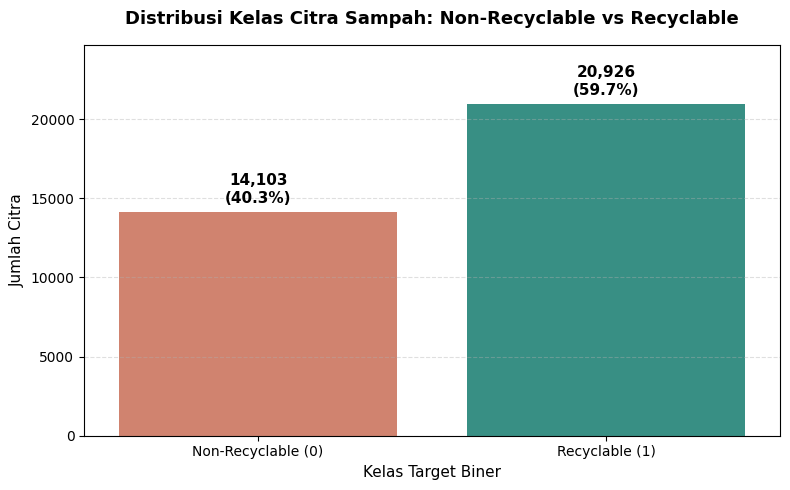

In [ ]:
# CELL 3: Visualisasi 1 - Distribusi Kelas (Bab 4.4)
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)
plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df_images,
    x="kategori",
    hue="kategori",
    palette=["#e07a5f", "#2a9d8f"],
    legend=False
)

total = len(df_images)
for p in ax.patches:
    count = int(p.get_height())
    pct = 100 * count / total
    ax.annotate(f"{count:,}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., count),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 5),
                textcoords='offset points')

plt.title("Distribusi Kelas Citra Sampah: Non-Recyclable vs Recyclable", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Kelas Target Biner", fontsize=11)
plt.ylabel("Jumlah Citra", fontsize=11)
plt.ylim(0, max(df_images["kategori"].value_counts()) * 1.18)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("figures/01_class_distribution.png", dpi=150)
plt.show()

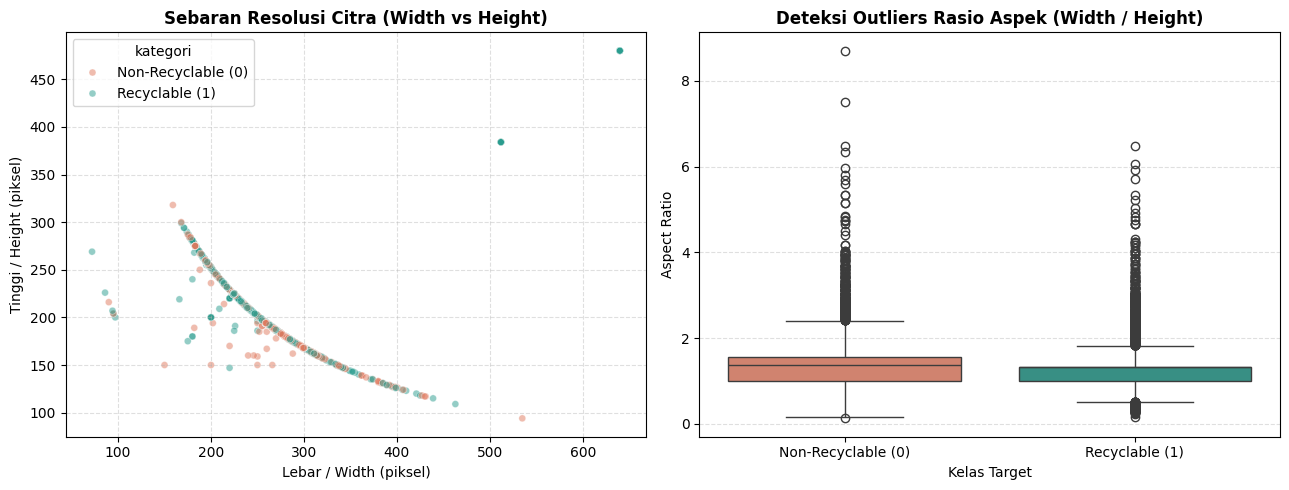

In [ ]:
# CELL 4: Visualisasi 2 - Distribusi Resolusi & Boxplot Aspect Ratio (Bab 4.4)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot kiri: Scatter plot Width vs Height
sample_df = df_images.sample(n=min(3000, len(df_images)), random_state=42)
sns.scatterplot(
    data=sample_df, x="width", y="height", hue="kategori",
    palette=["#e07a5f", "#2a9d8f"], alpha=0.5, s=25, ax=axes[0]
)
axes[0].set_title("Sebaran Resolusi Citra (Width vs Height)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Lebar / Width (piksel)")
axes[0].set_ylabel("Tinggi / Height (piksel)")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Subplot kanan: Boxplot Aspect Ratio untuk deteksi Outliers ukuran
sns.boxplot(
    data=df_images, x="kategori", y="aspect_ratio", hue="kategori",
    palette=["#e07a5f", "#2a9d8f"], legend=False, ax=axes[1]
)
axes[1].set_title("Deteksi Outliers Rasio Aspek (Width / Height)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kelas Target")
axes[1].set_ylabel("Aspect Ratio")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("figures/02_image_resolution_outliers.png", dpi=150)
plt.show()

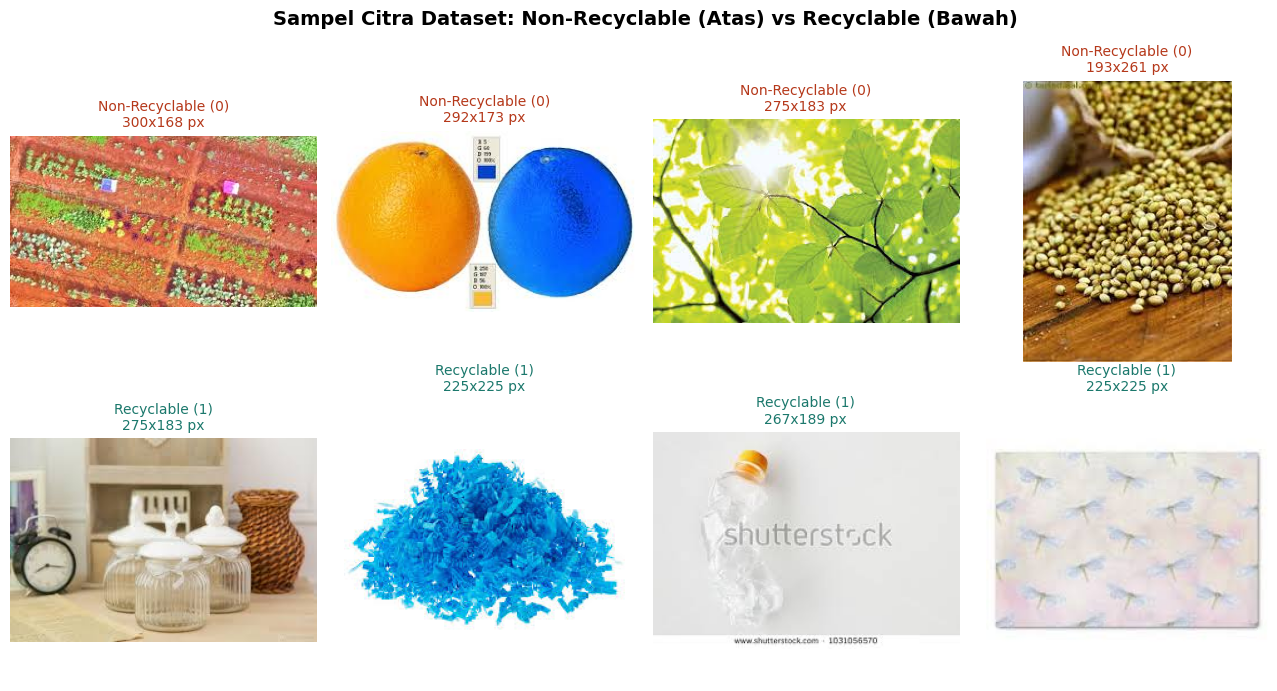

In [ ]:
# CELL 5: Visualisasi 3 - Contoh Sampel Citra & Distribusi Intensitas RGB (Bab 4.4)
import random

random.seed(42)
fig = plt.figure(figsize=(13, 7))

# Tampilkan 4 sampel Non-Recyclable (baris 1) dan 4 sampel Recyclable (baris 2)
non_rec_paths = df_images[(df_images["label_biner"]==0) & (df_images["color_mode"]=="RGB")]["image_path"].sample(4, random_state=42).tolist()
rec_paths = df_images[(df_images["label_biner"]==1) & (df_images["color_mode"]=="RGB")]["image_path"].sample(4, random_state=42).tolist()

for idx, p in enumerate(non_rec_paths):
    ax = plt.subplot(2, 4, idx + 1)
    img = Image.open(p)
    plt.imshow(img)
    plt.title(f"Non-Recyclable (0)\n{img.size[0]}x{img.size[1]} px", fontsize=10, color="#b5381a")
    plt.axis("off")

for idx, p in enumerate(rec_paths):
    ax = plt.subplot(2, 4, idx + 5)
    img = Image.open(p)
    plt.imshow(img)
    plt.title(f"Recyclable (1)\n{img.size[0]}x{img.size[1]} px", fontsize=10, color="#1b786c")
    plt.axis("off")

plt.suptitle("Sampel Citra Dataset: Non-Recyclable (Atas) vs Recyclable (Bawah)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/03_sample_images_grid.png", dpi=150)
plt.show()